# Rapport de Comparaison : LLM Labels vs Corrections Label Studio

## Résumé Exécutif

Ce notebook analyse la qualité du modèle LLM (Gemini) pour la classification des sentiments sur des commentaires YouTube en Darija marocain. Les résultats sont comparés avec les labels corrigés manuellement via Label Studio pour identifier les patterns d'erreur et les domaines d'amélioration.

## Objectifs:
- ✅ Calculer le taux d'erreur du modèle LLM après vérification humaine
- ✅ Identifier les confusions principales et leur impact
- ✅ Analyser les forces et faiblesses par catégorie de sentiment
- ✅ Fournir des recommandations basées sur les erreurs systématiques
- ✅ Présenter des exemples d'erreurs avec analyse détaillée

In [6]:
import json
import unicodedata
from pathlib import Path
from collections import defaultdict

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Configuration pour les graphiques
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (12, 6)

In [7]:
# Chemins des fichiers
original_path = Path('../data/labeled/llm_datasetG1.json')
corrected_path = Path('../data/labeled/final_filtered.json')

print(f"📂 Chargement depuis:")
print(f"   - Original: {original_path.name}")
print(f"   - Corrigé: {corrected_path.name}")

def normalize_label(value):
    if value is None:
        return None
    txt = str(value).strip()
    txt_norm = unicodedata.normalize('NFKD', txt)
    txt_norm = ''.join(ch for ch in txt_norm if not unicodedata.combining(ch)).lower()

    if txt_norm in {'positif', 'positive', 'pos'}:
        return 'Positif'
    if txt_norm in {'neutre', 'neutral', 'neutrre', 'neu'}:
        return 'Neutre'
    if txt_norm in {'negatif', 'negative', 'neg'}:
        return 'Négatif'
    return txt

with original_path.open('r', encoding='utf-8') as f:
    original_data = json.load(f)

with corrected_path.open('r', encoding='utf-8') as f:
    corrected_data = json.load(f)

df_orig = pd.DataFrame(original_data)
df_corr = pd.DataFrame(corrected_data)

df_orig['sentiment'] = df_orig['sentiment'].map(normalize_label)
df_corr['sentiment'] = df_corr['sentiment'].map(normalize_label)

print(f"\n📊 Dimensions:")
print(f"   - Commentaires originaux (LLM): {len(df_orig):,}")
print(f"   - Commentaires après correction: {len(df_corr):,}")
print(f"   - Réduction: {len(df_orig) - len(df_corr):,} ({((len(df_orig) - len(df_corr))/len(df_orig)*100):.1f}% supprimés)")

📂 Chargement depuis:
   - Original: llm_datasetG1.json
   - Corrigé: final_filtered.json

📊 Dimensions:
   - Commentaires originaux (LLM): 44,452
   - Commentaires après correction: 43,412
   - Réduction: 1,040 (2.3% supprimés)


Les commentaires supprimés incluent principalement des messages contenant des liens ou rédigés en arabe, français ou anglais, afin de garantir la cohérence et la qualité du dataset

In [9]:
df = pd.merge(
    df_orig,
    df_corr,
    on="comment_id",
    suffixes=("_llm", "_human")
)

print("Dataset fusionné :", len(df))
df.head()

Dataset fusionné : 43398


,comment_id,text_clean_llm,sentiment_llm,text_clean_human,sentiment_human,char_length,word_count,has_noise
0,UgxPJAXnO5KddWaG3MF4AaABAg,جيش 2026 اثبثو وجودكم,Neutre,جيش 2026 اثبثو وجودكم,Neutre,21,4,False
1,Ugz_QMCzryTBQXSfaX94AaABAg,تفرجت فهاد الفيديو كا تلميذ و كا استاد,Neutre,تفرجت فهاد الفيديو كا تلميذ و كا استاد,Neutre,38,8,False
2,UgyWgThaW-j2sDhmKnl4AaABAg,knt f cp fach khrj had lvideo db ana f 6eme,Neutre,knt f cp fach khrj had lvideo db ana f 6eme,Neutre,43,11,False
3,UgxyXyJEDGUmoQtGRSt4AaABAg,mazal hna2025,Neutre,mazal hna2025,Neutre,13,2,False
4,UgxPOwiYCsONTDsIqvV4AaABAg,لي كيتفرج من2025 يدير لايك,Neutre,لي كيتفرج من2025 يدير لايك,Neutre,26,5,False


VARIABLE DE COMPARAISON

In [10]:
df["correct"] = df["sentiment_llm"] == df["sentiment_human"]

correct = df["correct"].sum()
errors = len(df) - correct

accuracy = correct / len(df) * 100

print(f"Accuracy: {accuracy:.2f}%")
print(f"Errors: {errors}")

Accuracy: 96.81%
Errors: 1384


Le modèle LLM atteint une accuracy de 96.81%, avec 1384 erreurs sur l’ensemble du dataset.
Cela montre une performance globale élevée, mais avec quelques désaccords nécessitant une validation humaine

ANALYSE GLOBALE

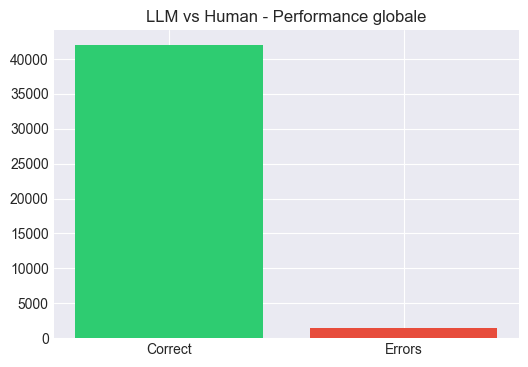

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

plt.bar(
    ["Correct", "Errors"],
    [correct, errors],
    color=["#2ECC71", "#E74C3C"]
)

plt.title("LLM vs Human - Performance globale")
plt.show()

ERREURS PAR CLASSE

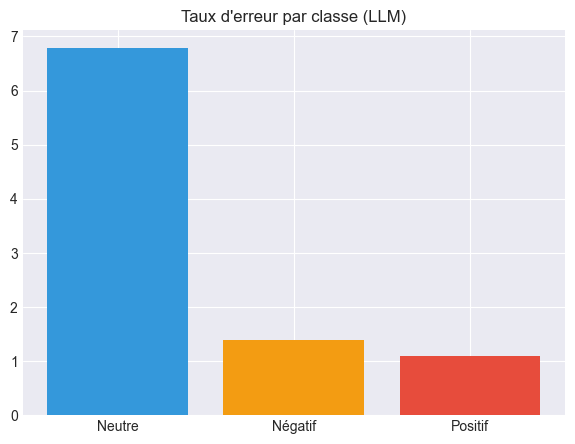

In [13]:
df_class = df.groupby("sentiment_llm")["correct"].apply(
    lambda x: 100 - x.mean()*100
).reset_index(name="error_rate")

plt.figure(figsize=(7,5))

plt.bar(
    df_class["sentiment_llm"],
    df_class["error_rate"],
    color=["#3498db", "#f39c12", "#e74c3c"]
)

plt.title("Taux d'erreur par classe (LLM)")
plt.show()

MATRICE DE CONFUSION

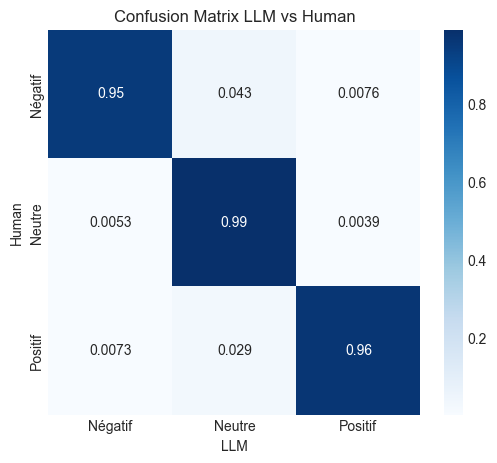

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# ordre des classes (important)
labels = ["Négatif", "Neutre", "Positif"]

cm = confusion_matrix(
    df["sentiment_human"],
    df["sentiment_llm"],
    labels=labels,
    normalize="true"
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix LLM vs Human")
plt.xlabel("LLM")
plt.ylabel("Human")

plt.show()

TOP ERREURS

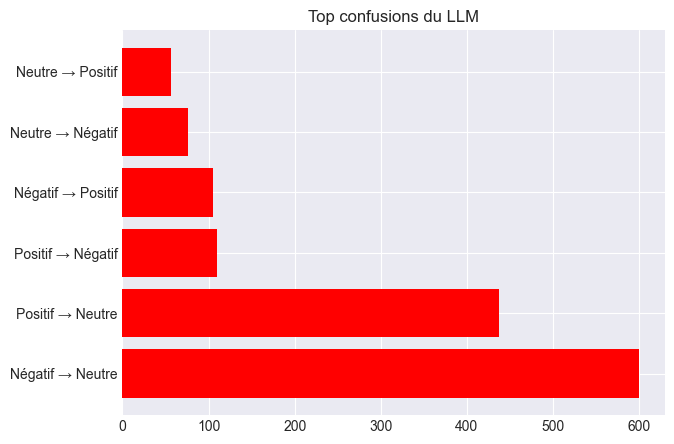

In [15]:
errors_df = df[df["correct"] == False]

top = (errors_df["sentiment_human"] + " → " + errors_df["sentiment_llm"]).value_counts().head(7)

plt.figure(figsize=(7,5))

plt.barh(top.index, top.values, color="red")

plt.title("Top confusions du LLM")
plt.show()

In [19]:
errors_df = df[df["correct"] == False].copy()

errors_df["correction_type"] = (
    errors_df["sentiment_llm"].astype(str).str.capitalize() +
    " → " +
    errors_df["sentiment_human"].astype(str).str.capitalize()
)

correction_types = errors_df["correction_type"].value_counts().index.tolist()

print("\n" + "═"*70)
print("        EXEMPLES DE CORRECTIONS HUMAINES PAR TYPE")
print("═"*70)

for ctype in correction_types:

    subset = errors_df[errors_df["correction_type"] == ctype]

    print(f"\n{'─'*70}")
    print(f"TYPE : {ctype} ({len(subset)} cas)")
    print(f"{'─'*70}")

    for i, row in enumerate(
        subset[["text_clean_llm", "sentiment_llm", "sentiment_human"]]
        .dropna()
        .head(3)
        .itertuples(),
        1
    ):
        print(f"\nExemple {i}")
        print("Commentaire :", row.text_clean_llm)
        print("LLM :", row.sentiment_llm)
        print("Humain :", row.sentiment_human)


══════════════════════════════════════════════════════════════════════
        EXEMPLES DE CORRECTIONS HUMAINES PAR TYPE
══════════════════════════════════════════════════════════════════════

──────────────────────────────────────────────────────────────────────
TYPE : Neutre → Négatif (600 cas)
──────────────────────────────────────────────────────────────────────

Exemple 1
Commentaire : cyprien dial jumia
LLM : Neutre
Humain : Négatif

Exemple 2
Commentaire : هه علام هاد سيد
LLM : Neutre
Humain : Négatif

Exemple 3
Commentaire : lyouma awal nhar kantgrissa f7yati lyoum
LLM : Neutre
Humain : Négatif

──────────────────────────────────────────────────────────────────────
TYPE : Neutre → Positif (437 cas)
──────────────────────────────────────────────────────────────────────

Exemple 1
Commentaire : khouya simo twahechna ce genre de video
LLM : Neutre
Humain : Positif

Exemple 2
Commentaire : شكون لي بحالي عنذو بزاف ديال الاحلام او مزال محقق حتي حاجه ابان هن الله ارزقنا كل ما تمانينا